# Particle trajectories and capture zones with `martpy.Trajectory`

Everything a MARTHE trajectory run produces, read through the project: the
seeding file (`.deptr`) the `.rma` points at, the grid (`permh`) to locate
cell records and size the masks, and `trajmar.out` written next to the `.rma`.

    read_trajectory  ->  Trajectory
        .to_shape        the paths, as points or lines, for QGIS
        .build_capture   the capture zone of every seeding point -> CaptureZone
        .build_mask      a boolean raster of it                   -> CaptureMask
        .summary         one row per seeding point
        .plot            all of the above on one map

The model used here is `cap_z/MRN_M400_L3_G200_v12a_steady_CZ` (35 seeding
points, 100 particles each, three layers, a 200 m gigogne in a 400 m grid).
Change `RMA` and `OUT` to run it on another one.

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import martpy as mart

RMA = r'../tests/data/mrn_traj/mrn_v11.rma'
OUT = r'traj_wdir'
os.makedirs(OUT, exist_ok=True)
pd.set_option('display.width', 160)

## 1. Read the run

`read_trajectory` (a shortcut for `Trajectory.from_project`) takes the `.rma`
path or a `MartProject`.  `trajmar.out` is looked for next to the `.rma`;
pass `trajmar=` to point elsewhere (a `.gz` is fine).  `crs` defaults to
Lambert-93.

In [6]:
tr = mart.read_trajectory(RMA)
print(tr)

Trajectory: 400 paths, 91307 vertices, 4 seeding points (0 unattributed)
    W01: 100 paths
    W02: 100 paths
    W03: 100 paths
    W04: 100 paths



What was read: the seeding points (with x, y filled from the grid for
cell records), and the vertices with their altitude `z`, travel time `t` and
`layer` -- the fifth column of `trajmar.out`, so no elevation lookup is
needed to know which layer a particle is in.

In [7]:
display(tr.seeds.head())

print(' vertices', len(tr.xy), 
      '\n z', tr.z.min().round(1), '..', tr.z.max().round(1),
      '\n layers', np.unique(tr.layer), 
      '\n cellsize (smallest)', tr._native_cellsize(), 'm')

,form,col,row,layer,inest,x,y,z,npart,radius,group
key,,,,,,,,,,,
W01,xy,-1,-1,-1,-1,567056.0,6933156.0,64.95,100,142.0,1
W02,xy,-1,-1,-1,-1,565802.0,6928087.0,14.66,100,142.0,20
W03,cell,152,45,3,1,566300.0,6941443.0,NaN,100,142.0,33
W04,cell,152,43,3,1,566300.0,6941843.0,NaN,100,142.0,4


 vertices 91307 
 z -15.8 .. 174.5 
 layers [1 3] 
 native cell (smallest) 200.0 m


### Which seeding point does a trajectory belong to?

MARTHE writes the `Group =` tag of a location trajectory (with sometime a single digit wrapped if run from WinMARTHE --a bug--).   `method='auto'`
(the default) trusts the tag only when every trajectory carries one, the `G=`
of the seeding file are unique and every tag is among them; otherwise it
falls back to the geometric test -- the N particles are released on the
circle of radius R about the seeding point, so |d - R| ~ 0 identifies it.

therefore sometime this build writes the full tag, and the two methods sometime disagree if two seeding points sit closer together than 2R if particles lie on the intersection of their rings. To avoid this it is better to define the *.deptr file in notebook and run it without WinMARTHE (if facing this issue).

In [9]:
ring = mart.read_trajectory(RMA, method='auto')
print('auto resolved to:', tr.method)

# check wheather the two method disagrees
d = np.flatnonzero(ring.owner != tr.owner)
print(len(d), 'trajectories differ:', [(tr.keys[tr.owner[j]], ring.keys[ring.owner[j]]) for j in d])

auto resolved to: group
0 trajectories differ: []


## 2. The paths as a shapefile / geopackage

Every feature carries `key` (W01 ...), `group` (the real `G=` tag) and `traj`.

* `kind='point'` -- one feature per vertex with the values exactly as
  `trajmar.out` writes them: `x, y, z, t, layer`.
* `kind='line'` -- one feature per pair of consecutive vertices, so a path can
  be classified along its length in QGIS: `from`, `to`, and `z`, `t` as the
  mean of the two ends, `layer` as the deeper of the two.

`id` selects seeding points: `-1` for all (default), a key (`'W03'`), the
`G=` group of the seeding record (`111`), a 1-based number in file order, or
a list of any of these -- a number is taken as a `G=` group when one seeding
point carries it, else as the file-order number.  The extension picks the
driver.

In [10]:
pts = tr.to_shape(os.path.join(OUT, 'paths_points_W01.shp'), kind='point', id="W01")
display(pts.head(3))

lines = tr.to_shape(os.path.join(OUT, 'paths_lines.gpkg'), kind='line', id=[20, 'W03'])
display(lines.head(3))

,key,group,traj,vertex,x,y,z,t,layer,geometry
0,W01,1,1,0,567056.0,6933298.0,64.95000,0.000000,3,POINT (567056 6933298)
1,W01,1,1,1,567056.2,6933307.0,64.95805,0.006767,3,POINT (567056.2 6933307)
2,W01,1,1,2,567056.5,6933316.0,64.96609,0.013533,3,POINT (567056.5 6933316)


,key,group,traj,seg,from,to,z,t,layer,geometry
0,W02,20,101,0,"(565802.00, 6928229.00)","(565842.90, 6928241.00)",14.66,0.010503,3,"LINESTRING (565802 6928229, 565842.9 6928241)"
1,W02,20,101,1,"(565842.90, 6928241.00)","(565883.10, 6928254.00)",14.66,0.031509,3,"LINESTRING (565842.9 6928241, 565883.1 6928254)"
2,W02,20,101,2,"(565883.10, 6928254.00)","(565922.70, 6928266.00)",14.66,0.052515,3,"LINESTRING (565883.1 6928254, 565922.7 6928266)"


## 3. Capture zones

The zone is the **envelope** of the pathlines (Tosco et al. 2008): the union
of the stream tubes between angularly adjacent trajectories.  MARTHE releases
the particles at equal angles on a ring about the seeding point, so sorting
them by seeding angle gives the true neighbour relation -- and every pathline
is then an edge of two tubes, so none can be left outside the zone drawn from
it.

`offset_m` is the standoff from the outermost pathline, and the only argument
that expands a zone.  `gap_factor` decides when two adjacent pathlines have
separated too far to be one stream tube (they have split around a stagnation
point), in which case the ribbon between them is left unfilled; `max_gap` sets
that distance outright, in metres.  `min_width`, `smooth` and `simplify` are
cosmetic.

In [11]:
cz = tr.build_capture(offset_m=20.)
print(cz)
display(cz.gdf.head())
cz.to_shape(os.path.join(OUT, 'capture_envelope.shp'))

CaptureZone(envelope): 4 zones, 62.764 km2


,key,group,x,y,ntraj,area_km2,method,geometry
0,W01,1,567056.0,6933156.0,100,16.6817,envelope,"POLYGON ((565064.056 6937270.749, 565064.062 6..."
1,W02,20,565802.0,6928087.0,100,20.6193,envelope,"POLYGON ((565620.442 6928092.803, 565620.435 6..."
2,W03,33,566300.0,6941443.0,100,2.8776,envelope,"POLYGON ((566118.442 6941448.82, 566118.429 69..."
3,W04,4,566300.0,6941843.0,100,22.5859,envelope,"POLYGON ((566118.447 6941848.853, 566118.355 6..."


'notebook_out\\capture_envelope.shp'

In [13]:
# what each threshold does, on one seeding point
areas = {}
for label, kw in [('default', {}), ('offset_m=0', {'offset_m': 0.}),
                  ('offset_m=100', {'offset_m': 100.}),
                  ('fill every gap', {'gap_factor': 0}),
                  ('max_gap=500 m', {'max_gap': 500.}),
                  ('smooth=50 m', {'smooth': 50.})]:
    z = tr.build_capture(id='W02', **kw)
    areas[label] = float(z.gdf.area_km2.iloc[0])
pd.Series(areas, name='W02 km2').round(2)

default           20.62
offset_m=0        18.85
offset_m=100      28.03
fill every gap    32.20
max_gap=500 m     20.62
smooth=50 m       20.66
Name: W02 km2, dtype: float64

A zone always encloses the pathlines it was built from -- that is the property
the stream-tube construction gives, and it is worth checking on your own model:

In [14]:
from shapely.geometry import MultiPoint

cz = tr.build_capture(offset_m=20.)
for key, zone in cz.gdf.set_index('key').geometry.items():
    sel = tr.paths_of(tr.keys.index(key))
    pts = MultiPoint(np.concatenate([tr.xy[tr.start[j]:tr.start[j+1]] for j in sel]))
    print(key, 'encloses every one of its pathlines:', zone.buffer(1e-6).covers(pts))

W01 encloses every one of its pathlines: True
W02 encloses every one of its pathlines: True
W03 encloses every one of its pathlines: True
W04 encloses every one of its pathlines: True


## 4. Capture masks

This module has been added to generate capture probability of a model grid cell, for stochastic studies. The `build_mask` can be called and the mask can be saved `save_mask` in a loop for each set of model realisation for further grid based probability determination.

`build_mask` marks the cells a particle path runs through, on the model's
own grid: the main grid and every gigogne, at their own sizes, layer by
layer, taking the layer MARTHE writes with each vertex.  There is no cell
size to choose -- it is the model's -- so masks of different runs of the same
model are directly comparable, cell for cell.

Each seeding point gets its own plane, and the mask is written back as a
MARTHE grid file (`.tmask`): one block per layer and per gigogne, 1 where a
path runs through the cell.  It reopens with `martpy.grid.load_marthe_grid`
like any other field of the model.

In [15]:
cm = tr.build_mask()          # on the MARTHE cells 
print(cm)
print('finest cell: %g m | model cells: %d' % (cm.grid.min_cell, cm.grid.nzone))

# the mask is 3D in the way the model is: per gigogne, per layer
cm.cells_by_layer()

CaptureMask: 4 seeding point(s), 832 cells of the MARTHE grid in layer(s) [1, 3], 80.800 km2
finest cell: 200 m | model cells: 352968


,grid,layer,cells,area_km2
0,0,1,0,0.00
1,0,2,0,0.00
2,0,3,396,63.36
3,1,1,2,0.08
4,1,2,0,0.00
5,1,3,434,17.36


In [16]:
# written as a MARTHE grid, and read like any other field
p = cm.save_mask(os.path.join(OUT, 'mrn_v11.tmask'))
print(open(p, encoding='ISO-8859-1').read(180))

from martpy.utils.trajectory import CaptureMask
back = CaptureMask.load_mask(p)
print('identical after reload:', (back.any == cm.any).all(),
      '| cells', int(back.any.sum()), '| %.2f km2' % back.area_km2())

# one file per seeding point, for a per-well mask
print([os.path.basename(f) for f in
       cm.save_mask(os.path.join(OUT, 'well.tmask'), by_id=True)])

Marthe_Grid Version=9.0
Title=Particle path mask (all seeding points)
[Infos]
Field=TMASK
Type=
Elem_Number=0
Name=
Time_Step=-9999
Time=0
Layer=1
Max_Layer=3
Nest_grid=0
Max_NestG
identical after reload: True | cells 832 | 80.80 km2
['well_W01.tmask', 'well_W02.tmask', 'well_W03.tmask', 'well_W04.tmask']


## 5. Summary table

One row per seeding point: the seed as declared (`group` is its `G=` tag),
how many paths it got and
by which attribution, mean path length, longest travel time, then the area
of whatever has been built so far (NaN for a seed a product does not
cover).

In [17]:
tr.build_capture(offset_m=20.)
tr.build_mask()
summ = tr.summary()
summ.to_csv(os.path.join(OUT, 'summary.csv'))
summ.head(10)

,group,x,y,z,layer,radius,npart,ntraj,method,path_m,t_max,capture_method,capture_km2,mask_cells,mask_km2
key,,,,,,,,,,,,,,,
W01,1,567056.0,6933156.0,64.95,3,142.0,100,100,group,3392.521885,1094.881,envelope,16.6817,189,21.959999
W02,20,565802.0,6928087.0,14.66,3,142.0,100,100,group,13645.482978,31824.180,envelope,20.6193,324,28.080000
W03,33,566300.0,6941443.0,NaN,3,142.0,100,100,group,9387.096388,1026.131,envelope,2.8776,52,6.760000
W04,4,566300.0,6941843.0,NaN,3,142.0,100,100,group,8756.983218,3672.509,envelope,22.5859,319,31.240000


The difference between two methology/area captured can be plotted with native `pandas.plot()`

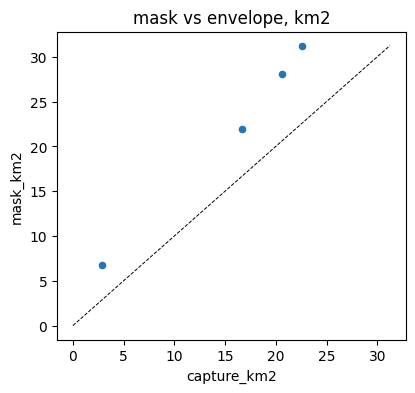

In [18]:
ax = summ.plot.scatter('capture_km2', 'mask_km2', figsize=(4.5, 4))
lim = summ[['capture_km2', 'mask_km2']].max().max()
ax.plot([0, lim], [0, lim], 'k--', lw=0.7)
ax.set_title('mask vs envelope, km2');

## 6. Maps

`plot` draws any combination of the paths, the capture polygons and the mask
(`path`, `capture`, `cz_mask` -- the last two need their `build_*` first),
plus the seeding points.  Paths are coloured by `layer` (legend) or by
altitude `z` (colorbar), or drawn plain with `color_by=None`.  Every cosmetic
choice is a keyword: `base_fontsize` scales every text on the figure,
`font`, `figsize`, the colours, the map furniture, and the basemap
(`basemap_source` is one of esri / esri_gray / esri_street / esri_imagery /
topo / positron / voyager / osm or any XYZ URL; `tile` is the zoom).  It
returns `(fig, ax)` and draws on a given `ax`.

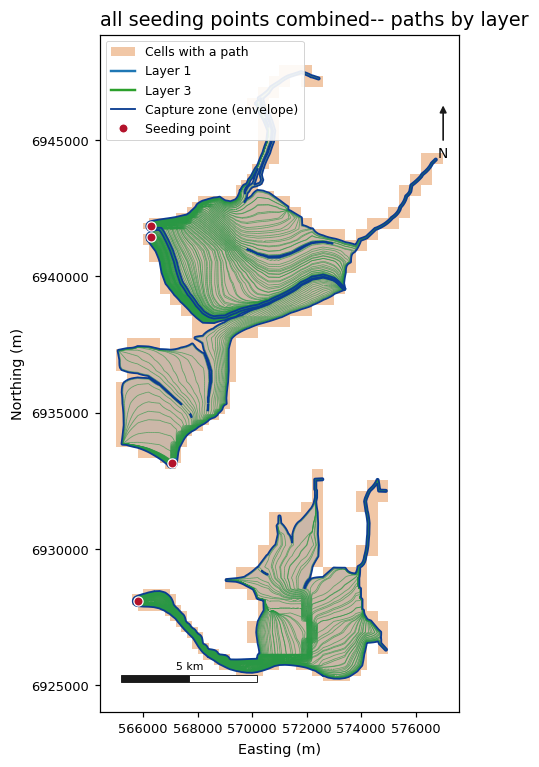

In [19]:
tr.plot(capture=True, cz_mask=True, color_by='layer', basemap=False,
        title='all seeding points combined-- paths by layer', figsize=(9, 8));

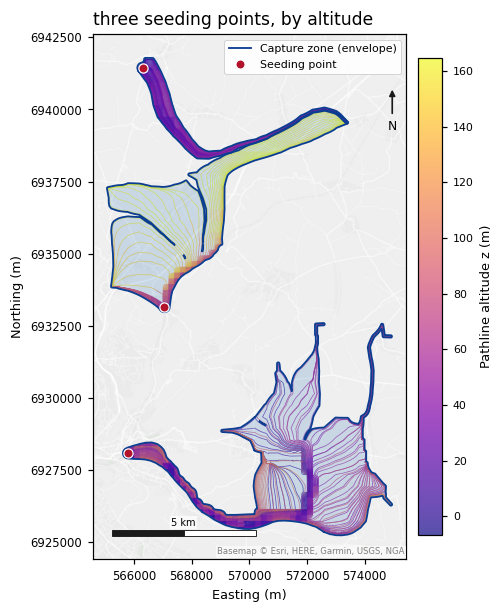

In [20]:
tr.plot(capture=True, color_by='z', cmap='plasma', id=["W01", 2, 33],
        basemap=True, basemap_source='esri_gray', title='three seeding points, by altitude',
        base_fontsize=8, save=os.path.join(OUT, 'W01_W03_z.png'));

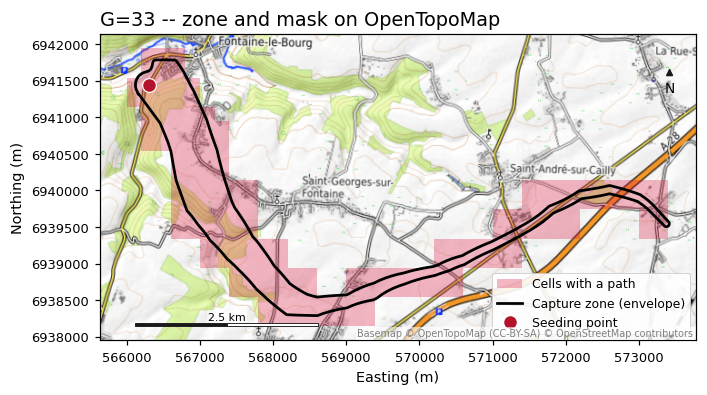

In [21]:
tr.plot(path=False, capture=True, cz_mask=True, id='33',
        basemap=True, basemap_source='topo', tile=13,
        zone_color='black', zone_fill='none', zone_width=1.8,
        mask_color='crimson', mask_alpha=0.3, seed_size=9,
        legend_loc='lower right', title='G=33 -- zone and mask on OpenTopoMap');

## 7. Without a project

The two readers stand on their own when there is no `.rma` at hand, and the
class can be built from their output.  Without seeding points the paths are
grouped by the `Group =` tag of `trajmar.out` (keys `G1`, `G2` ...), or all
together under `ALL` when the file carries none.

In [16]:
from martpy.utils.trajectory import Trajectory, read_deptr, read_trajmar

test = os.path.join(os.path.dirname(mart.__file__), '..', '..', 'tests', 'data', 'traj')
henry = Trajectory(read_deptr(os.path.join(test, 'Henry_Perma.deptr')),
                   read_trajmar(os.path.join(test, 'trajmar.out')))
print(henry)
henry.summary()

Trajectory: 40 paths, 3927 vertices, 1 seeding points (0 unattributed)
    ALL: 40 paths



,group,x,y,z,layer,radius,npart,ntraj,method,path_m,t_max
key,,,,,,,,,,,
ALL,-1,100.0,-0.5,NaN,1,NaN,-1,40,none,87.030493,80.0


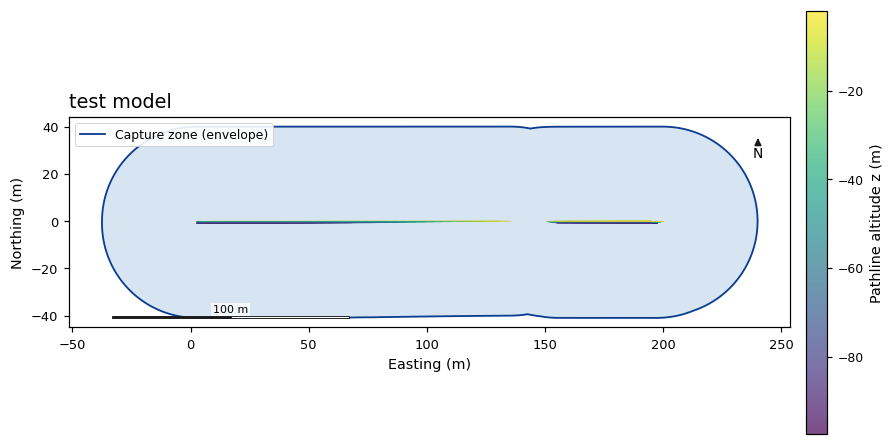

In [17]:
henry_cz = henry.build_capture(offset_m=20.0)

henry.plot(capture=True, cz_mask=False, color_by='z', basemap=False,
        title='test model', figsize=(9, 5));